### Problem 20 : Unlearning at scale - a year of deletion requests

⏱️ ~40 min · 🧭 Stage 8 (Extensions) · 📄 Bourtoule et al. 2021 (SISA), Guo et al. 2020 (certified removal), Problem 17's capacity plan

> 🔗 **Building on Problems 7 and 17 :** Problem 7 built SISA and removed *one* request. Problem 17 planned how many
> requests a team can serve before the deadline. Real services do not get one request. They get a steady stream,
> every week, for years. This problem asks what happens to each method when the requests keep coming.

Three questions, one per step :

| question | what we measure |
|---|---|
| how does the bill grow with the size of the service? | total cost of a year of requests, for each strategy |
| does SISA stay cheap when requests come in batches? | shards touched per batch : the formula, then a real run |
| do the exact classical updates scale to big models? | memory and time of one Newton removal as the model grows |

**Cost unit :** as in Problems 15 and 17, one *example-gradient* is one training example passed through the model
once. A full retrain of our digit model costs `epochs × rows` example-gradients.

In [1]:
# On Google Colab? Run this cell first : it fetches the course library (mul/) and the diagrams. Locally it does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("mul"):
    !git clone -q --depth 1 https://github.com/Shreyan1/machine-unlearning-course.git
    %cd machine-unlearning-course
    !pip install -q fairlearn

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import lab, train, methods, classical, viz
viz.style()

L = lab.make_lab("random")                     # we only use its train/test split; every training row is one user
X, y = L.X_train, L.y_train
N = len(X)
SISA_RECIPE = dict(n_slices=4, epochs_per_slice=15)
print(f"{N} users in the training set, {len(L.X_test)} test images")

1257 users in the training set, 540 test images


#### Step 1 : Train - the service and its request stream

The service is the digit classifier from the rest of the course. Every training row belongs to one user.
Over a year, users ask to be deleted at a steady rate : we use **2 requests a week**, picked at random, so about 8%
of users leave in a year. The law gives us a deadline : GDPR says "without undue delay", and at most **one month**.

We train the service three ways : one model (as usual), SISA with 5 shards, and SISA with 20 shards.

In [3]:
rng = np.random.default_rng(2026)                # its own seed: SISA uses seed 0 to split the shards
WEEKS, PER_WEEK = 52, 2
stream = rng.permutation(N)[:WEEKS * PER_WEEK].reshape(WEEKS, PER_WEEK)   # stream[w] = users who ask in week w

t0 = time.perf_counter()
mono = train.fit(lab.model_fn, X, y, seed=0, **lab.FIT)
RETRAIN_COST = lab.FIT["epochs"] * N                                        # example-gradients for one full retrain
mono_seconds = time.perf_counter() - t0

sisa = {}
for K in [5, 20]:
    s = methods.SISA(lab.model_fn, n_shards=K, **SISA_RECIPE)
    info = s.fit(X, y)
    sisa[K] = dict(model=s, fit_cost=info["samples_processed"])

rows = [("one model", train.accuracy(mono, L.X_test, L.y_test), RETRAIN_COST)]
rows += [(f"SISA, {K} shards", train.accuracy(v["model"], L.X_test, L.y_test), v["fit_cost"]) for K, v in sisa.items()]
print(pd.DataFrame(rows, columns=["model", "test accuracy", "training cost (example-gradients)"]).to_string(index=False))
print(f"\nrequests in the year: {stream.size}  ({stream.size / N:.1%} of users)")

          model  test accuracy  training cost (example-gradients)
      one model       0.979630                              75420
 SISA, 5 shards       0.979630                              47205
SISA, 20 shards       0.955556                              47610

requests in the year: 104  (8.3% of users)


#### Step 2 : Show the issue - retraining for every request does not scale

The gold standard is to retrain from scratch for every request. That is affordable for our 1,257 users. But think
about how the bill grows. If a service is twice as big, **each retrain costs twice as much, and there are twice as many
requests** (the same share of users leave). So the yearly bill grows with the *square* of the size.

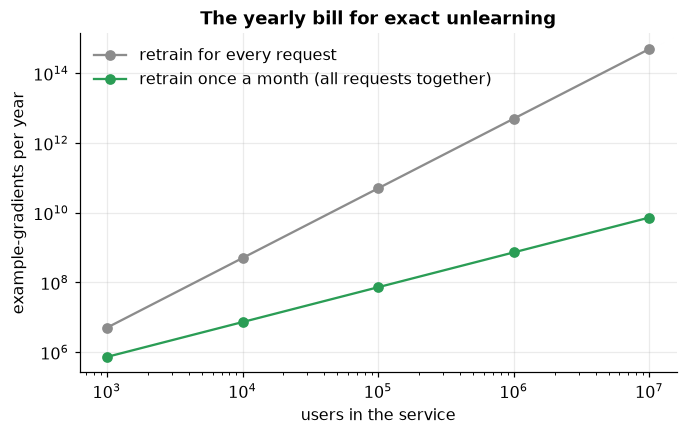

     1,000 users   every request:   5.0e+06   monthly batch:   7.2e+05   ratio        7x
    10,000 users   every request:   5.0e+08   monthly batch:   7.2e+06   ratio       69x
   100,000 users   every request:   5.0e+10   monthly batch:   7.2e+07   ratio      689x
 1,000,000 users   every request:   5.0e+12   monthly batch:   7.2e+08   ratio     6895x
10,000,000 users   every request:   5.0e+14   monthly batch:   7.2e+09   ratio    68947x


In [4]:
sizes = np.array([1e3, 1e4, 1e5, 1e6, 1e7])
rate = stream.size / N                                    # share of users who leave per year
per_request = lab.FIT["epochs"] * sizes                   # one retrain
year_bill = per_request * rate * sizes                    # requests per year x cost per retrain

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(sizes, year_bill, "o-", color=viz.ORIGINAL, label="retrain for every request")
ax.loglog(sizes, per_request * 12, "o-", color=viz.RETRAIN, label="retrain once a month (all requests together)")
ax.set_xlabel("users in the service"); ax.set_ylabel("example-gradients per year")
ax.set_title("The yearly bill for exact unlearning"); ax.legend()
plt.show()

for n, a, b in zip(sizes, year_bill, per_request * 12):
    print(f"{int(n):>10,d} users   every request: {a:9.1e}   monthly batch: {b:9.1e}   ratio {a / b:8.0f}x")

Look at the ratio. At 1,000 users, retraining for every request costs about 7 times more than retraining once a
month. At 10 million users it is more than 60,000 times more. **One retrain per request is fine for a small service
and impossible for a big one.**

Batching is the simplest fix : collect the requests and serve them together, still inside the one-month deadline.
The monthly retrain costs the same no matter how many requests it carries. But it still costs a *full* retrain every
month. Can SISA do better?

#### Step 3 : Untrain - SISA under a stream of requests

Problem 7 showed that SISA removes one user by retraining only that user's shard, and only from the slice that held
them. With `K` shards, one request costs about `1/K` of a retrain, often less.

But with a batch of `b` requests, many shards are hit. If users are spread at random, the expected number of shards
touched is

$$\mathbb{E}[\text{shards touched}] = K\left(1 - \left(1 - \tfrac{1}{K}\right)^{b}\right)$$

For `K = 5` and `b = 8` (one month of our requests) that is already 4.2 of the 5 shards. **Big batches make SISA cost
almost as much as a full retrain.** Let us check the formula against real runs.

In [5]:
def touched_formula(K, b):
    return K * (1 - (1 - 1 / K) ** b)

batch_sizes = [1, 2, 4, 8, 16, 32]
meas = []
for K in [5, 20]:
    for b in batch_sizes:
        trials = []
        for t in range(3):                                         # 3 different random batches per size
            s = methods.SISA(lab.model_fn, n_shards=K, **SISA_RECIPE)
            s.fit(X, y)
            batch = np.random.default_rng(100 + t).choice(N, b, replace=False)
            _, info = s.unlearn(batch)
            trials.append((info["shards_retrained"], info["samples_processed"] / sisa[K]["fit_cost"]))
        meas.append(dict(K=K, batch=b, touched=np.mean([a for a, _ in trials]),
                         formula=touched_formula(K, b), cost=np.mean([c for _, c in trials])))
meas = pd.DataFrame(meas)
print(meas.round(2).to_string(index=False))

 K  batch  touched  formula  cost
 5      1     1.00     1.00  0.14
 5      2     1.33     1.80  0.22
 5      4     2.67     2.95  0.43
 5      8     4.33     4.16  0.73
 5     16     4.67     4.86  0.85
 5     32     5.00     5.00  0.94
20      1     1.00     1.00  0.03
20      2     2.00     1.95  0.05
20      4     4.00     3.71  0.13
20      8     7.33     6.73  0.24
20     16    10.67    11.20  0.38
20     32    15.33    16.13  0.65


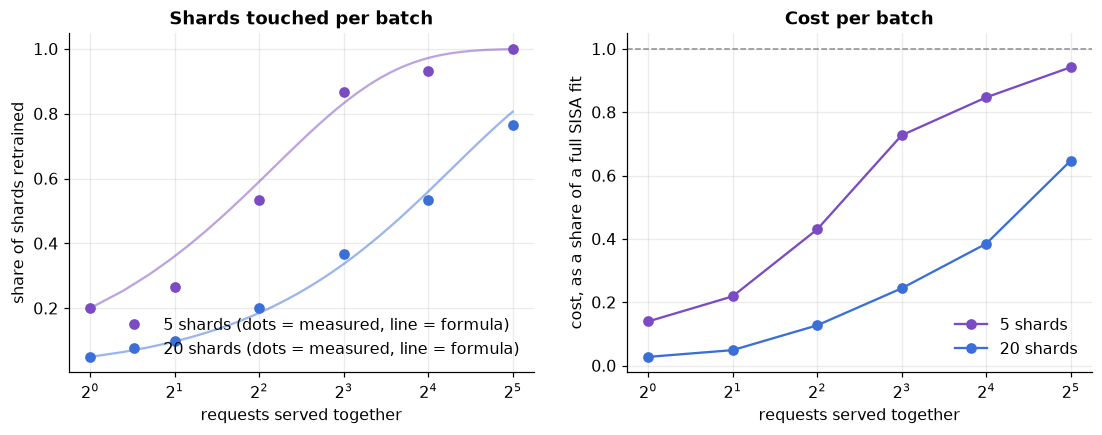

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for K, c in [(5, viz.METHOD), (20, viz.RETAIN)]:
    m = meas[meas.K == K]
    bb = np.linspace(1, 32, 100)
    axes[0].plot(bb, touched_formula(K, bb) / K, color=c, alpha=0.5)
    axes[0].plot(m.batch, m.touched / K, "o", color=c, label=f"{K} shards (dots = measured, line = formula)")
    axes[1].plot(m.batch, m.cost, "o-", color=c, label=f"{K} shards")
axes[0].set(xlabel="requests served together", ylabel="share of shards retrained", title="Shards touched per batch")
axes[1].set(xlabel="requests served together", ylabel="cost, as a share of a full SISA fit", title="Cost per batch")
axes[1].axhline(1, color=viz.ORIGINAL, ls="--", lw=1)
for ax in axes: ax.legend(); ax.set_xscale("log", base=2)
plt.show()

The formula matches the real runs. Two things to notice :

- Cost per batch is **below** the share of shards touched. That is the slices at work : a request in the last slice
  of a shard only replays that last slice.
- With 20 shards, a batch of 8 still leaves most shards alone. More shards keep SISA cheap under bigger batches.

So why not use 100 shards? Because each shard model sees less data and gets worse. That is the price of SISA :

In [7]:
acc = []
for K in [1, 2, 5, 10, 20, 40]:
    s = methods.SISA(lab.model_fn, n_shards=K, **SISA_RECIPE)
    s.fit(X, y)
    acc.append(dict(shards=K, rows_per_shard=N // K, test_accuracy=train.accuracy(s, L.X_test, L.y_test),
                    one_request_cost=1 / K, month_batch_cost=touched_formula(K, 8) / K))
acc = pd.DataFrame(acc)
print(acc.round(3).to_string(index=False))

 shards  rows_per_shard  test_accuracy  one_request_cost  month_batch_cost
      1            1257          0.978             1.000             1.000
      2             628          0.981             0.500             0.996
      5             251          0.980             0.200             0.832
     10             125          0.963             0.100             0.570
     20              62          0.956             0.050             0.337
     40              31          0.928             0.025             0.183


There is no free lunch : going from 1 to 40 shards makes one request about 40 times cheaper, and costs a few points of
accuracy (the exact numbers are in the table). Bigger services feel this less, because each shard still has plenty of
data. That is why SISA is used at large scale, where `N / K` is still a big number.

Now the whole year. Four strategies, each run for real on our 104 requests :

| strategy | what it does |
|---|---|
| retrain each | full retrain of the one model for every request (the gold standard, done naively) |
| retrain monthly | one full retrain every 4 weeks, with all requests from that month |
| SISA-20 each | SISA with 20 shards, every request served on its own, straight away |
| SISA-20 monthly | SISA with 20 shards, one batch every 4 weeks |

In [8]:
def run_year(strategy):
    """Serve the 52-week stream. Returns the total cost and the longest wait (in weeks) of any request."""
    if strategy.startswith("retrain"):
        every = 1 if strategy == "retrain each" else 4
        batches = [stream[w:w + every].ravel() for w in range(0, WEEKS, every)]
        n_retrains = len(batches) * (PER_WEEK if every == 1 else 1)
        return n_retrains * RETRAIN_COST, every - 1 if every > 1 else 0
    s = methods.SISA(lab.model_fn, n_shards=20, **SISA_RECIPE)
    s.fit(X, y)
    total, every = 0, (1 if strategy == "SISA-20 each" else 4)
    for w in range(0, WEEKS, every):
        reqs = stream[w:w + every].ravel()
        groups = [[r] for r in reqs] if every == 1 else [reqs]
        for g in groups:
            _, info = s.unlearn(g)
            total += info["samples_processed"]
    return total, every - 1 if every > 1 else 0, s

year = {}
for strat in ["retrain each", "retrain monthly", "SISA-20 each", "SISA-20 monthly"]:
    out = run_year(strat)
    year[strat] = dict(cost=out[0], longest_wait_weeks=out[1])
    if strat == "SISA-20 monthly":
        sisa_after_year = out[2]
year = pd.DataFrame(year).T
year["cost vs retrain each"] = year["cost"] / year.loc["retrain each", "cost"]
year["inside 1-month deadline"] = year["longest_wait_weeks"] < 4.3
print(year.to_string())

                    cost  longest_wait_weeks  cost vs retrain each  inside 1-month deadline
retrain each     7843680                   0              1.000000                     True
retrain monthly   980460                   3              0.125000                     True
SISA-20 each      183075                   0              0.023340                     True
SISA-20 monthly   151995                   3              0.019378                     True


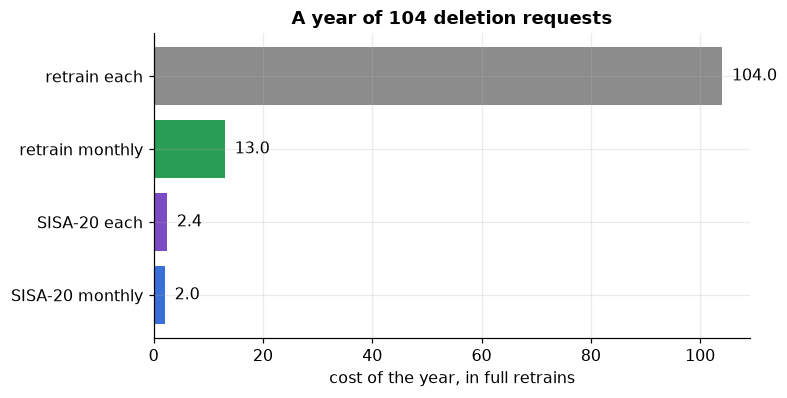

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = [viz.ORIGINAL, viz.RETRAIN, viz.METHOD, viz.RETAIN]
ax.barh(year.index[::-1], year["cost"][::-1] / RETRAIN_COST, color=colors[::-1])
for i, v in enumerate(year["cost"][::-1] / RETRAIN_COST):
    ax.text(v, i, f"  {v:.1f}", va="center")
ax.set_xlabel("cost of the year, in full retrains"); ax.set_title("A year of 104 deletion requests")
plt.show()

Batching cuts the cost of plain retraining by 8 times (8 requests share one retrain). For SISA it saves much less,
under a fifth, because a month's batch of 8 still touches about 7 of the 20 shards : the requests do not share much
work. So SISA can serve every request **straight away**, nobody waits, and it is still about 5 times cheaper than
retraining the one model once a month. **How much batching helps depends on the method.** Use the formula to check
before you choose a window, and always stay inside the legal deadline.

##### Exact classical updates : do they scale to big models?

Problem 2 removed points from logistic regression with one Newton step, with a certificate : the gradient on the
remaining data is (almost) zero. Guo et al. (2020) turned this into *certified removal*, and the idea is used in
practice for linear models. Two questions at scale :

1. Does the small error of each step pile up over many requests?
2. What does one step cost as the model grows?

In [10]:
# 1) 26 monthly-sized removals in a row (4 requests each), with Newton steps only, never a full refit
newton = classical.SoftmaxNewton(lam=1.0).fit(X, y, n_classes=10)
keep, cur, trail = np.ones(N, bool), newton, []
for i, w in enumerate(range(0, WEEKS, 2)):
    keep[stream[w:w + 2].ravel()] = False
    cur = cur.unlearn_newton(X[keep], y[keep])
    exact = classical.SoftmaxNewton(1.0).fit(X[keep], y[keep], n_classes=10, w0=cur.w)
    trail.append(dict(step=i + 1, removed=int((~keep).sum()), grad_norm=cur.grad_norm(X[keep], y[keep]),
                      max_weight_gap=float(np.abs(cur.w - exact.w).max())))
trail = pd.DataFrame(trail)
print(trail.iloc[[0, 5, 12, 19, 25]].round(5).to_string(index=False))
print(f"\nbudget used (sum of gradient norms over the year): {trail.grad_norm.sum():.3f}")

 step  removed  grad_norm  max_weight_gap
    1        4    0.03978         0.00165
    6       24    0.02115         0.00078
   13       52    0.01118         0.00048
   20       80    0.00304         0.00009
   26      104    0.02362         0.00087

budget used (sum of gradient norms over the year): 0.527


The error does **not** pile up. Each Newton step starts from the current weights and moves to the optimum of the data
that is left, so it also corrects what the earlier steps missed. The weight gap to an exact refit stays tiny all year.

There is a catch for certified removal, though. Guo et al. hide the small leftover gradient with random noise, and
each removal *uses up* part of a fixed budget (in their analysis, the leftover gradients add up). When the budget is
gone, you must retrain from scratch. The line printed above is that running total. So even exact-looking updates
come with a scheduled full retrain.

The bigger problem is cost. A Newton step needs the Hessian : a square table with one row and one column per weight.

In [11]:
proj_rng = np.random.default_rng(0)
cost_rows = []
for d in [64, 128, 256, 384]:
    P = proj_rng.normal(size=(64, d)) / 8.0
    Xd = np.tanh(X @ P)                                  # random features: a model with d inputs per class
    m = classical.SoftmaxNewton(lam=1.0, max_iter=1).fit(Xd, y, n_classes=10)
    t0 = time.perf_counter()
    m.unlearn_newton(Xd[keep], y[keep])
    secs = time.perf_counter() - t0
    p = (d + 1) * 10
    cost_rows.append(dict(weights=p, hessian_MB=p * p * 8 / 1e6, newton_step_seconds=secs))
cost_rows = pd.DataFrame(cost_rows)
print(cost_rows.round(3).to_string(index=False))

for name, p in [("our MLP (Problem 4)", sum(w.size for w in mono.params)), ("a small LLM (1 billion weights)", 1e9)]:
    print(f"{name:32s} {p:>14,.0f} weights   Hessian would need {p * p * 8 / 1e9:,.1f} GB")

 weights  hessian_MB  newton_step_seconds
     650       3.380                0.006
    1290      13.313                0.022
    2570      52.839                0.115
    3850     118.580                0.325
our MLP (Problem 4)                      85,002 weights   Hessian would need 57.8 GB
a small LLM (1 billion weights)   1,000,000,000 weights   Hessian would need 8,000,000,000.0 GB


Double the weights and the Hessian needs four times the memory, and one step takes about five to eight times longer.
At about 4,000 weights one step already takes a quarter of a second. Our small MLP from Problem 4 has 85,000 weights, and its Hessian would
need around 58 GB. For a billion-weight language model it would be 8 billion GB. **The exact
classical updates are great for linear models and impossible for deep ones.** That is why deep models need SISA
(exact by design) or approximate methods (which Problems 8-11 and 19 showed you cannot trust without an audit).

#### Step 4 : Show the result - a policy for the year

Putting it together for our service :

In [12]:
policy = pd.DataFrame([
    ["linear / logistic model", "Newton removal for each request", "full retrain when the noise budget runs out", "tiny"],
    ["small deep model", "retrain once a month", "batch everything inside the deadline", "1 retrain / month"],
    ["large deep model", "SISA with many shards, as requests arrive", "accept a few points of accuracy for cheap deletes",
     f"{year.loc['SISA-20 each', 'cost vs retrain each']:.1%} of retrain-each"],
    ["any model", "never: approximate method alone", "only with an audit (Problem 11) and a scheduled exact retrain", "-"],
], columns=["model", "serve requests with", "and also", "yearly cost here"])
print(policy.to_string(index=False))

                  model                       serve requests with                                                      and also     yearly cost here
linear / logistic model           Newton removal for each request                   full retrain when the noise budget runs out                 tiny
       small deep model                      retrain once a month                          batch everything inside the deadline    1 retrain / month
       large deep model SISA with many shards, as requests arrive             accept a few points of accuracy for cheap deletes 2.3% of retrain-each
              any model           never: approximate method alone only with an audit (Problem 11) and a scheduled exact retrain                    -


#### Step 5 : Prove it

Cheap is only useful if it is still exact. After a whole year of SISA-20 batches, the model must be **bit-for-bit**
the SISA model you would get by training from scratch on the users who are left. We train that fresh model, with the
same data layout minus every deleted user, and compare every weight.

In [13]:
deleted = set(stream.ravel().tolist())
layout = [[np.asarray(sl, dtype=int) for sl in shard] for shard in sisa_after_year.slices]
assert not any(int(i) in deleted for shard in layout for sl in shard for i in sl), "a deleted user is still in the data"

fresh = methods.SISA(lab.model_fn, n_shards=20, **SISA_RECIPE)
fresh.fit(X, y, partition=layout)
same = all(train.weights_equal(a, b) for a, b in zip(sisa_after_year.shard_models, fresh.shard_models))
print(f"users deleted over the year            : {len(deleted)}")
print(f"deleted users left in the data layout : 0")
print(f"after a year of batches == fresh SISA  : {same}   (all 20 shard models, every weight)")
print(f"test accuracy after the year           : {train.accuracy(sisa_after_year, L.X_test, L.y_test):.3f}")

users deleted over the year            : 104
deleted users left in the data layout : 0
after a year of batches == fresh SISA  : True   (all 20 shard models, every weight)
test accuracy after the year           : 0.952


And for the Newton path, the certificate after the year : the gradient of the remaining data at the served weights.

In [14]:
print(f"Newton path after {len(trail)} removals:  gradient norm on the remaining data = {trail.grad_norm.iloc[-1]:.4f}")
print(f"largest gap to an exact refit                       = {trail.max_weight_gap.max():.2e}")
print(f"same predictions as the exact refit on the test set : "
      f"{(cur.predict(L.X_test) == exact.predict(L.X_test)).mean():.1%}")

Newton path after 26 removals:  gradient norm on the remaining data = 0.0236
largest gap to an exact refit                       = 5.39e-03
same predictions as the exact refit on the test set : 100.0%


----
#### OUTCOME :

| question | answer |
|---|---|
| how does the bill grow? | retrain-per-request grows with the **square** of the service size; batching inside the deadline brings it back to linear |
| does SISA survive a stream? | yes, and the formula predicts its cost; batches touch many shards, so batching saves SISA little and requests can be served straight away |
| is SISA still exact after a year? | yes : bit-for-bit equal to a fresh SISA model without the deleted users |
| do exact Newton updates scale? | their error does not pile up, but the Hessian grows with the square of the weights : fine for linear models, impossible for deep ones |

#### Key Takeaways :

- **Scale changes the answer, not the goal.** The target is still the retrained model. What changes is which way of
  reaching it you can afford.
- **Batch to the method.** Batching saves plain retraining a lot and SISA little. Pick the window with the formula,
  and always inside the legal deadline.
- **Shards cost accuracy.** More shards mean cheaper deletes and weaker shard models. Measure both before choosing `K`.
- **Certified removal needs a retrain schedule.** Every removal uses part of the budget; plan the full retrain in
  advance, as Problem 17's capacity plan does.

❓ **Open question :** all our requests were random users. What happens to SISA when the people who leave are *not*
random, for example when a whole region or customer leaves at once? (Hint : Problem 7's user-aware partitions and
Problem 12's skewed deletions.)

#### TASK :

1. Change `PER_WEEK` to 10. Which strategy wins now? Use the formula to predict before you run it.
2. Find the batch size at which SISA-20 costs as much as one full retrain of the one model.
3. Put all the users of one digit class in the same shard (pass a `partition` to `SISA.fit`) and delete that class.
   How much does it cost, and what happens to accuracy on that class?